In [3]:
import pandas as pd

# Load the two datasets
train = pd.read_csv('../data/train.csv', low_memory=False)
store = pd.read_csv('../data/store.csv')

# Basic look
print(train.shape)
print(train.head())
print(train.info())

(1017209, 9)
   Store  DayOfWeek        Date  Sales  Customers  Open  Promo StateHoliday  \
0      1          5  2015-07-31   5263        555     1      1            0   
1      2          5  2015-07-31   6064        625     1      1            0   
2      3          5  2015-07-31   8314        821     1      1            0   
3      4          5  2015-07-31  13995       1498     1      1            0   
4      5          5  2015-07-31   4822        559     1      1            0   

   SchoolHoliday  
0              1  
1              1  
2              1  
3              1  
4              1  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  object
 3   Sales          1017209 non-null  int64 
 4   Customers  

In [4]:
train.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [5]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  object
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(2)
memory usage: 69.8+ MB


In [6]:
store.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   object 
 2   Assortment                 1115 non-null   object 
 3   CompetitionDistance        1112 non-null   float64
 4   CompetitionOpenSinceMonth  761 non-null    float64
 5   CompetitionOpenSinceYear   761 non-null    float64
 6   Promo2                     1115 non-null   int64  
 7   Promo2SinceWeek            571 non-null    float64
 8   Promo2SinceYear            571 non-null    float64
 9   PromoInterval              571 non-null    object 
dtypes: float64(5), int64(2), object(3)
memory usage: 87.2+ KB


In [7]:
train['Date'] = pd.to_datetime(train['Date'])
train.dtypes

Store                     int64
DayOfWeek                 int64
Date             datetime64[ns]
Sales                     int64
Customers                 int64
Open                      int64
Promo                     int64
StateHoliday             object
SchoolHoliday             int64
dtype: object

In [8]:
df = train.merge(store, on='Store', how='left')
print(df.shape)
df.head()

(1017209, 18)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [9]:
df.isnull().sum()

Store                             0
DayOfWeek                         0
Date                              0
Sales                             0
Customers                         0
Open                              0
Promo                             0
StateHoliday                      0
SchoolHoliday                     0
StoreType                         0
Assortment                        0
CompetitionDistance            2642
CompetitionOpenSinceMonth    323348
CompetitionOpenSinceYear     323348
Promo2                            0
Promo2SinceWeek              508031
Promo2SinceYear              508031
PromoInterval                508031
dtype: int64

In [11]:
# Only 2,642 missing — likely just unrecorded, fill with median
df['CompetitionDistance'] = df['CompetitionDistance'].fillna(df['CompetitionDistance'].median())

In [12]:
df['CompetitionOpenSinceMonth'] = df['CompetitionOpenSinceMonth'].fillna(0)
df['CompetitionOpenSinceYear'] = df['CompetitionOpenSinceYear'].fillna(0)

In [13]:
df['Promo2SinceWeek'] = df['Promo2SinceWeek'].fillna(0)
df['Promo2SinceYear'] = df['Promo2SinceYear'].fillna(0)
df['PromoInterval'] = df['PromoInterval'].fillna('None')

In [14]:
df.isnull().sum()

Store                        0
DayOfWeek                    0
Date                         0
Sales                        0
Customers                    0
Open                         0
Promo                        0
StateHoliday                 0
SchoolHoliday                0
StoreType                    0
Assortment                   0
CompetitionDistance          0
CompetitionOpenSinceMonth    0
CompetitionOpenSinceYear     0
Promo2                       0
Promo2SinceWeek              0
Promo2SinceYear              0
PromoInterval                0
dtype: int64

In [15]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df['WeekOfYear'] = df['Date'].dt.isocalendar().week

df[['Date', 'Year', 'Month', 'Day', 'WeekOfYear']].head()

,Date,Year,Month,Day,WeekOfYear
0,2015-07-31,2015,7,31,31
1,2015-07-31,2015,7,31,31
2,2015-07-31,2015,7,31,31
3,2015-07-31,2015,7,31,31
4,2015-07-31,2015,7,31,31


In [16]:
df = df.sort_values(['Store', 'Date']).reset_index(drop=True)

In [17]:
df['Sales_Lag_7'] = df.groupby('Store')['Sales'].shift(7)
df['Sales_Lag_14'] = df.groupby('Store')['Sales'].shift(14)

df[['Store', 'Date', 'Sales', 'Sales_Lag_7', 'Sales_Lag_14']].head(15)

,Store,Date,Sales,Sales_Lag_7,Sales_Lag_14
0,1,2013-01-01,0,NaN,NaN
1,1,2013-01-02,5530,NaN,NaN
2,1,2013-01-03,4327,NaN,NaN
3,1,2013-01-04,4486,NaN,NaN
4,1,2013-01-05,4997,NaN,NaN
5,1,2013-01-06,0,NaN,NaN
6,1,2013-01-07,7176,NaN,NaN
7,1,2013-01-08,5580,0.0,NaN
8,1,2013-01-09,5471,5530.0,NaN
9,1,2013-01-10,4892,4327.0,NaN


In [18]:
df['Sales_RollingMean_7'] = df.groupby('Store')['Sales'].transform(lambda x: x.shift(1).rolling(7).mean())
df['Sales_RollingMean_30'] = df.groupby('Store')['Sales'].transform(lambda x: x.shift(1).rolling(30).mean())

df[['Store', 'Date', 'Sales', 'Sales_RollingMean_7', 'Sales_RollingMean_30']].head(35)

,Store,Date,Sales,Sales_RollingMean_7,Sales_RollingMean_30
0,1,2013-01-01,0,NaN,NaN
1,1,2013-01-02,5530,NaN,NaN
2,1,2013-01-03,4327,NaN,NaN
3,1,2013-01-04,4486,NaN,NaN
4,1,2013-01-05,4997,NaN,NaN
5,1,2013-01-06,0,NaN,NaN
6,1,2013-01-07,7176,NaN,NaN
7,1,2013-01-08,5580,3788.000000,NaN
8,1,2013-01-09,5471,4585.142857,NaN
9,1,2013-01-10,4892,4576.714286,NaN


In [19]:
df[['Sales_Lag_7', 'Sales_Lag_14', 'Sales_RollingMean_7', 'Sales_RollingMean_30']].isnull().sum()

Sales_Lag_7              7805
Sales_Lag_14            15610
Sales_RollingMean_7      7805
Sales_RollingMean_30    33450
dtype: int64

In [20]:
before = df.shape[0]
df = df.dropna(subset=['Sales_Lag_7', 'Sales_Lag_14', 'Sales_RollingMean_7', 'Sales_RollingMean_30'])
after = df.shape[0]

print(f"Dropped {before - after} rows")
print(f"Remaining rows: {after}")

Dropped 33450 rows
Remaining rows: 983759


In [21]:
# Check: does Sales=0 always match Open=0?
print(df[df['Sales'] == 0]['Open'].value_counts())

Open
0    167129
1        51
Name: count, dtype: int64


In [22]:
df = df[df['Open'] == 1]
print(df.shape)

(816630, 26)


In [23]:
# Is today a holiday of any kind (state or school)?
df['IsHoliday'] = ((df['StateHoliday'] != '0') | (df['SchoolHoliday'] == 1)).astype(int)

# Is this store currently running Promo2 (long-term promo)?
df['IsPromo2Active'] = df['Promo2']

# Competition age in months (how long has a competitor been nearby)
df['CompetitionOpenMonths'] = (df['Year'] - df['CompetitionOpenSinceYear']) * 12 + (df['Month'] - df['CompetitionOpenSinceMonth'])
df['CompetitionOpenMonths'] = df['CompetitionOpenMonths'].apply(lambda x: x if x > 0 else 0)

df[['Date', 'IsHoliday', 'Promo', 'IsPromo2Active', 'CompetitionOpenMonths']].head()

,Date,IsHoliday,Promo,IsPromo2Active,CompetitionOpenMonths
30,2013-01-31,0,0,0,52.0
31,2013-02-01,0,0,0,53.0
32,2013-02-02,0,0,0,53.0
34,2013-02-04,0,1,0,53.0
35,2013-02-05,0,1,0,53.0


In [24]:
df[['Date', 'IsHoliday', 'Promo', 'IsPromo2Active', 'CompetitionOpenMonths']].head()

,Date,IsHoliday,Promo,IsPromo2Active,CompetitionOpenMonths
30,2013-01-31,0,0,0,52.0
31,2013-02-01,0,0,0,53.0
32,2013-02-02,0,0,0,53.0
34,2013-02-04,0,1,0,53.0
35,2013-02-05,0,1,0,53.0


In [25]:
# Features we'll use to predict Sales
feature_cols = [
    'Store', 'DayOfWeek', 'Promo', 'SchoolHoliday', 'IsHoliday',
    'Year', 'Month', 'Day', 'WeekOfYear',
    'Sales_Lag_7', 'Sales_Lag_14', 'Sales_RollingMean_7', 'Sales_RollingMean_30',
    'CompetitionDistance', 'CompetitionOpenMonths', 'Promo2', 'IsPromo2Active'
]

X = df[feature_cols]
y = df['Sales']

print(X.shape, y.shape)
X.dtypes

(816630, 17) (816630,)


Store                      int64
DayOfWeek                  int64
Promo                      int64
SchoolHoliday              int64
IsHoliday                  int64
Year                       int32
Month                      int32
Day                        int32
WeekOfYear                UInt32
Sales_Lag_7              float64
Sales_Lag_14             float64
Sales_RollingMean_7      float64
Sales_RollingMean_30     float64
CompetitionDistance      float64
CompetitionOpenMonths    float64
Promo2                     int64
IsPromo2Active             int64
dtype: object

In [26]:
# Sort by date to ensure proper time-based split
df = df.sort_values('Date')

split_date = '2015-06-01'  # last ~2 months as test set
train_data = df[df['Date'] < split_date]
test_data = df[df['Date'] >= split_date]

X_train = train_data[feature_cols]
y_train = train_data['Sales']
X_test = test_data[feature_cols]
y_test = test_data['Sales']

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

Train size: (758019, 17)
Test size: (58611, 17)


In [27]:
# Baseline: predict using just the 7-day rolling average (naive forecast)
baseline_pred = X_test['Sales_RollingMean_7']

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

print(f"Baseline MAE: {baseline_mae:.2f}")
print(f"Baseline RMSE: {baseline_rmse:.2f}")

Baseline MAE: 1681.33
Baseline RMSE: 2437.52


In [28]:
import xgboost as xgb

model = xgb.XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"XGBoost MAE: {mae:.2f}")
print(f"XGBoost RMSE: {rmse:.2f}")

XGBoost MAE: 663.40
XGBoost RMSE: 940.39


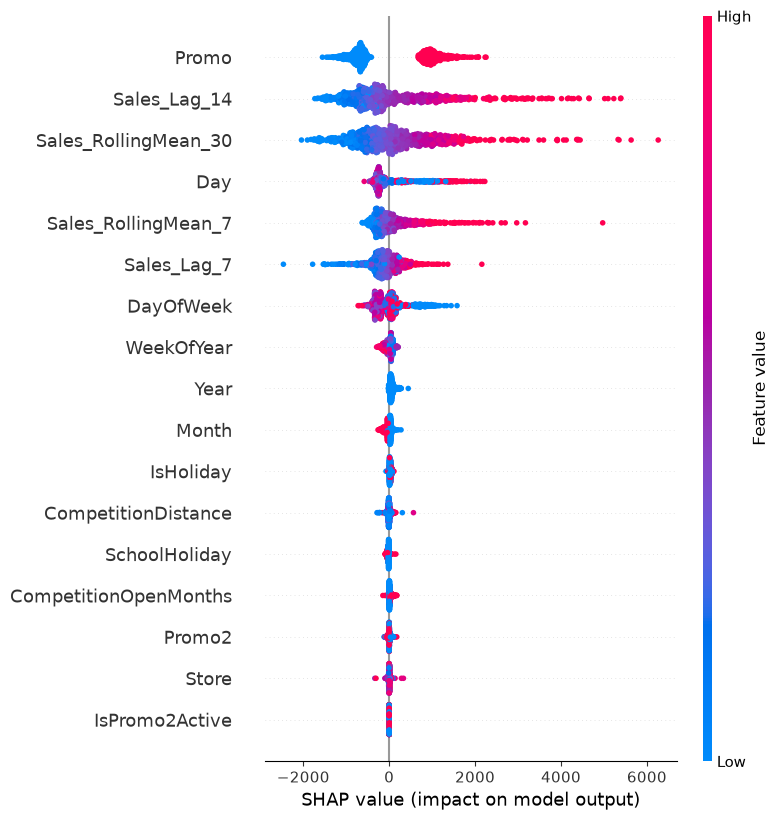

In [29]:
import shap

# Use a sample of test data for speed (SHAP can be slow on huge datasets)
X_sample = X_test.sample(1000, random_state=42)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_sample)

# Summary plot: shows which features matter most overall
shap.summary_plot(shap_values, X_sample)

In [30]:
import joblib

joblib.dump(model, '../src/xgboost_sales_model.pkl')
print("Model saved successfully")

Model saved successfully


In [31]:
test_data = test_data.copy()
test_data['Predicted_Sales'] = y_pred
test_data['Error'] = test_data['Sales'] - test_data['Predicted_Sales']
test_data['Abs_Error'] = test_data['Error'].abs()

test_data[['Store', 'Date', 'Sales', 'Predicted_Sales', 'Error']].head(10)

,Store,Date,Sales,Predicted_Sales,Error
167585,185,2015-06-01,10839,11976.345703,-1137.345703
924766,1014,2015-06-01,20098,18015.115234,2082.884766
499595,548,2015-06-01,8539,9210.394531,-671.394531
953232,1045,2015-06-01,11768,12263.713867,-495.713867
143439,158,2015-06-01,10363,11408.124023,-1045.124023
423595,464,2015-06-01,12689,14472.941406,-1783.941406
31231,34,2015-06-01,11231,13170.962891,-1939.962891
742461,815,2015-06-01,7489,9270.000977,-1781.000977
45751,50,2015-06-01,7980,8038.712402,-58.712402
545591,598,2015-06-01,6797,8401.915039,-1604.915039


In [32]:
mean_error = test_data['Error'].mean()
std_error = test_data['Error'].std()

test_data['Error_Zscore'] = (test_data['Error'] - mean_error) / std_error
test_data['Is_Anomaly'] = test_data['Error_Zscore'].abs() > 2.5

print("Total anomalies flagged:", test_data['Is_Anomaly'].sum())
print("Percentage of test data:", round(test_data['Is_Anomaly'].mean() * 100, 2), "%")

Total anomalies flagged: 1305
Percentage of test data: 2.23 %


In [33]:
anomalies = test_data[test_data['Is_Anomaly']].sort_values('Abs_Error', ascending=False)
anomalies[['Store', 'Date', 'Sales', 'Predicted_Sales', 'Error', 'Error_Zscore']].head(15)


,Store,Date,Sales,Predicted_Sales,Error,Error_Zscore
828270,909,2015-06-22,41551,10652.176758,30898.823242,33.572396
265095,292,2015-06-29,29161,9202.423828,19958.576172,21.749629
828271,909,2015-06-23,30038,11659.158203,18378.841797,20.042462
798854,876,2015-07-06,27330,9221.195312,18108.804688,19.750642
828298,909,2015-07-20,23081,8853.741211,14227.258789,15.555982
828277,909,2015-06-29,6125,19824.310547,-13699.310547,-14.623346
828268,909,2015-06-20,22882,9334.910156,13547.089844,14.820946
798855,876,2015-07-07,23927,10616.911133,13310.088867,14.564827
265096,292,2015-06-30,23584,10972.888672,12611.111328,13.809465
828279,909,2015-07-01,3547,15088.079102,-11541.079102,-12.291016


In [34]:
import os
from dotenv import load_dotenv
import google.generativeai as genai

load_dotenv()
genai.configure(api_key=os.getenv("GEMINI_API_KEY"))

print("Gemini configured successfully")

Gemini configured successfully


C:\Users\Administrator\AppData\Local\Temp\ipykernel_29512\679460787.py:3: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  import google.generativeai as genai


In [42]:
# Overall performance summary
overall_summary = f"""
Total predictions evaluated: {len(test_data)}
Baseline MAE: {baseline_mae:.2f}
XGBoost MAE: {mae:.2f}
Improvement over baseline: {round((1 - mae/baseline_mae) * 100, 1)}%

Anomalies detected: {test_data['Is_Anomaly'].sum()} ({round(test_data['Is_Anomaly'].mean()*100, 2)}% of test data)
"""

# Top 5 anomalies, formatted simply
top_anomalies = anomalies[['Store', 'Date', 'Sales', 'Predicted_Sales', 'Error']].head(5)
anomaly_text = top_anomalies.to_string(index=False)

print(overall_summary)
print(anomaly_text)


Total predictions evaluated: 58611
Baseline MAE: 1681.33
XGBoost MAE: 663.40
Improvement over baseline: 60.5%

Anomalies detected: 1305 (2.23% of test data)

 Store       Date  Sales  Predicted_Sales        Error
   909 2015-06-22  41551     10652.176758 30898.823242
   292 2015-06-29  29161      9202.423828 19958.576172
   909 2015-06-23  30038     11659.158203 18378.841797
   876 2015-07-06  27330      9221.195312 18108.804688
   909 2015-07-20  23081      8853.741211 14227.258789


In [43]:
prompt = f"""
You are a data analyst writing a weekly sales performance summary for store managers.

Here is the model performance and anomaly data:

{overall_summary}

Top anomalies (biggest gaps between predicted and actual sales):
{anomaly_text}

Write a short, clear business report (150-200 words) that:
1. Summarizes how well the forecasting model performed
2. Highlights which stores had unusual sales behavior and whether they sold more or less than expected
3. Suggests 1-2 possible business reasons worth investigating
4. Uses plain English, no technical jargon (avoid words like MAE, RMSE, z-score)
"""

model_gemini = genai.GenerativeModel('gemini-2.0-flash')
response = model_gemini.generate_content(prompt)

print(response.text)

DefaultCredentialsError: 
  No API_KEY or ADC found. Please either:
    - Set the `GOOGLE_API_KEY` environment variable.
    - Manually pass the key with `genai.configure(api_key=my_api_key)`.
    - Or set up Application Default Credentials, see https://ai.google.dev/gemini-api/docs/oauth for more information.

In [40]:
import os
from dotenv import load_dotenv

load_dotenv()
key = os.getenv("GEMINI_API_KEY")

print("Key found:", key is not None)
print("Key preview:", key[:8] + "..." if key else "NOTHING FOUND")

Key found: False
Key preview: NOTHING FOUND


In [41]:
Get-ChildItem -Recurse -Filter ".env*"

SyntaxError: invalid syntax (1331375558.py, line 1)

In [45]:
from dotenv import load_dotenv
import os

load_dotenv(dotenv_path='../src/.env')
key = os.getenv("GEMINI_API_KEY")
print("Key found:", key is not None)
print("Key preview:", key[:8] + "..." if key else "NOTHING FOUND")

Key found: False
Key preview: NOTHING FOUND


In [46]:
import os

# What folder is the notebook actually running from?
print("Current working directory:", os.getcwd())

# List files in that directory and one level up
print("\nFiles in current dir:", os.listdir('.'))
print("\nFiles in parent dir:", os.listdir('..'))

Current working directory: c:\Users\Administrator\Desktop\sales-forecast-project\notebooks

Files in current dir: ['01_eda.ipynb']

Files in parent dir: ['.env', 'data', 'notebooks', 'requirements.txt', 'src']


In [47]:
from dotenv import load_dotenv
import os

result = load_dotenv(dotenv_path='../.env')
print("load_dotenv returned:", result)

key = os.getenv("GEMINI_API_KEY")
print("Key found:", key is not None)
print("Key preview:", key[:8] + "..." if key else "NOTHING FOUND")

load_dotenv returned: True
Key found: True
Key preview: AQ.Ab8RN...


In [48]:
import google.generativeai as genai

genai.configure(api_key=key)
print("Gemini configured successfully")

Gemini configured successfully


In [49]:
model_gemini = genai.GenerativeModel('gemini-2.0-flash')
response = model_gemini.generate_content(prompt)

print(response.text)

ResourceExhausted: 429 You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. 
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 0, model: gemini-2.0-flash
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 0, model: gemini-2.0-flash
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_input_token_count, limit: 0, model: gemini-2.0-flash
Please retry in 12.574234498s. [links {
  description: "Learn more about Gemini API quotas"
  url: "https://ai.google.dev/gemini-api/docs/rate-limits"
}
, violations {
  quota_metric: "generativelanguage.googleapis.com/generate_content_free_tier_requests"
  quota_id: "GenerateRequestsPerDayPerProjectPerModel-FreeTier"
  quo

In [50]:
try:
    model_gemini = genai.GenerativeModel('gemini-2.0-flash')
    response = model_gemini.generate_content("Say hello in one sentence.")
    print(response.text)
except Exception as e:
    print("ERROR TYPE:", type(e).__name__)
    print("ERROR MESSAGE:", str(e))

ERROR TYPE: ResourceExhausted
ERROR MESSAGE: 429 You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. 
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_input_token_count, limit: 0, model: gemini-2.0-flash
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 0, model: gemini-2.0-flash
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 0, model: gemini-2.0-flash
Please retry in 50.892053137s. [links {
  description: "Learn more about Gemini API quotas"
  url: "https://ai.google.dev/gemini-api/docs/rate-limits"
}
, violations {
  quota_metric: "generativelanguage.googleapis.com/generate_content_free_tier_input_token_count"
  quota_id: "GenerateContentInputT

In [54]:
from groq import Groq
import os

groq_client = Groq(api_key=os.getenv("GROQ_API_KEY"))

response = groq_client.chat.completions.create(
    model="llama-3.3-70b-versatile",
    messages=[
        {"role": "user", "content": prompt}
    ]
)

print(response.choices[0].message.content)

This week's sales forecast showed significant improvement over our baseline predictions, with an error reduction of 60.5%. However, our model detected 1,305 unusual sales patterns, making up 2.23% of our test data. 

Some stores had notably unusual sales behavior. Store 909 had multiple days with much higher sales than predicted, including June 22nd and 23rd, with shortfalls in predicted sales of over $30,000. Store 292 also had a significant surprise on June 29th, selling nearly $20,000 more than expected. 

These discrepancies may be worth investigating to understand the cause. Possible reasons could include local events or promotions that our model wasn't aware of. For example, Store 909 might have hosted a successful promotion or event on those days, drawing in more customers than usual. By exploring these anomalies, we can refine our forecasting model and improve our understanding of what drives sales in our stores.


In [52]:
from dotenv import load_dotenv
load_dotenv(dotenv_path='../.env', override=True)

True

In [55]:
from groq import Groq
import os

groq_client = Groq(api_key=os.getenv("GROQ_API_KEY"))

response = groq_client.chat.completions.create(
    model="llama-3.3-70b-versatile",
    messages=[
        {"role": "user", "content": prompt}
    ]
)

print(response.choices[0].message.content)

Weekly Sales Performance Summary:

Our sales forecasting model performed well, improving its accuracy by 60.5% compared to our baseline prediction. However, we did identify some unusual sales patterns at a few stores. Specifically, stores 909, 292, and 876 had sales that significantly differed from our predictions. In each of these cases, the stores sold more than expected, with store 909 having the largest discrepancies on June 22 and 23.

These unusual sales spikes may be worth investigating further. Possible reasons could include successful in-store promotions or events that drew in more customers than usual. For example, it's possible that store 909 hosted a popular sale or event on June 22 and 23, driving up sales. We recommend reviewing store-level marketing initiatives and event calendars to see if they coincide with these unexpected sales increases. By understanding what drove these anomalies, we can refine our forecasting model and improve our ability to predict sales in the f

In [64]:
import sys
sys.path.append('../src')

from data_prep import prepare_full_dataset

df = prepare_full_dataset(data_dir='../data')
print(df.shape)
df.head()

ImportError: cannot import name 'prepare_full_dataset' from 'data_prep' (c:\Users\Administrator\Desktop\sales-forecast-project\notebooks\../src\data_prep.py)

In [61]:
with open('../src/data_prep.py', 'r') as f:
    content = f.read()
print(content)

import pandas as pd
import numpy as np


def load_data(data_dir='../data'):
    """Load raw train and store CSVs."""
    train = pd.read_csv(f'{data_dir}/train.csv', low_memory=False)
    store = pd.read_csv(f'{data_dir}/store.csv')
    return train, store


def clean_and_merge(train, store):
    """Merge train with store info and fix missing values."""
    train['Date'] = pd.to_datetime(train['Date'])
    df = train.merge(store, on='Store', how='left')

    # Fix missing values logically
    df['CompetitionDistance'] = df['CompetitionDistance'].fillna(df['CompetitionDistance'].median())
    df['CompetitionOpenSinceMonth'] = df['CompetitionOpenSinceMonth'].fillna(0)
    df['CompetitionOpenSinceYear'] = df['CompetitionOpenSinceYear'].fillna(0)
    df['Promo2SinceWeek'] = df['Promo2SinceWeek'].fillna(0)
    df['Promo2SinceYear'] = df['Promo2SinceYear'].fillna(0)
    df['PromoInterval'] = df['PromoInterval'].fillna('None')

    return df


def engineer_features(df):
    """Add calendar, l

In [63]:
import ast

with open('../src/data_prep.py', 'r') as f:
    tree = ast.parse(f.read())

functions = [node.name for node in ast.walk(tree) if isinstance(node, ast.FunctionDef)]
print("Functions found in file:", functions)

Functions found in file: ['load_data', 'clean_and_merge', 'engineer_features', 'get_feature_columns', 'prepare_full_dataset']


In [65]:
import sys
sys.path.append('../src')

import data_prep
print("Imported from:", data_prep.__file__)
print(dir(data_prep))

Imported from: c:\Users\Administrator\Desktop\sales-forecast-project\notebooks\../src\data_prep.py
['__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'clean_and_merge', 'engineer_features', 'load_data', 'np', 'pd']


In [66]:
import sys

# Remove any cached version of the module
for mod_name in list(sys.modules.keys()):
    if 'data_prep' in mod_name:
        del sys.modules[mod_name]

print("Cache cleared")

Cache cleared


In [67]:
import sys
sys.path.append('../src')

import data_prep
print("Imported from:", data_prep.__file__)
print(dir(data_prep))

Imported from: c:\Users\Administrator\Desktop\sales-forecast-project\notebooks\../src\data_prep.py
['__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'clean_and_merge', 'engineer_features', 'get_feature_columns', 'load_data', 'np', 'pd', 'prepare_full_dataset']


In [68]:
from data_prep import prepare_full_dataset

df = prepare_full_dataset(data_dir='../data')
print(df.shape)
df.head()

(816630, 29)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,Month,Day,WeekOfYear,Sales_Lag_7,Sales_Lag_14,Sales_RollingMean_7,Sales_RollingMean_30,IsHoliday,IsPromo2Active,CompetitionOpenMonths
30,1,4,2013-01-31,4709,571,1,0,0,0,c,...,1,31,5,5195.0,4044.0,4108.571429,4124.066667,0,0,52.0
31,1,5,2013-02-01,5633,658,1,0,0,0,c,...,2,1,5,5586.0,4127.0,4039.142857,4281.033333,0,0,53.0
32,1,6,2013-02-02,5970,701,1,0,0,0,c,...,2,2,5,5598.0,5182.0,4045.857143,4284.466667,0,0,53.0
34,1,1,2013-02-04,7032,762,1,1,0,0,c,...,2,4,6,4055.0,5394.0,4099.000000,4189.700000,0,0,53.0
35,1,2,2013-02-05,6049,678,1,1,0,0,c,...,2,5,6,3725.0,5720.0,4524.285714,4257.533333,0,0,53.0


In [69]:
import sys
for mod_name in list(sys.modules.keys()):
    if 'train_model' in mod_name or 'data_prep' in mod_name:
        del sys.modules[mod_name]

from train_model import run_full_training

model, test_data, y_pred, mae, rmse = run_full_training(
    data_dir='../data',
    model_out_path='../src/xgboost_sales_model.pkl'
)

Model trained and saved to ../src/xgboost_sales_model.pkl
MAE: 663.40 | RMSE: 940.39


In [70]:
import sys
for mod_name in list(sys.modules.keys()):
    if 'report_generator' in mod_name:
        del sys.modules[mod_name]

from report_generator import detect_anomalies, build_summary_text, generate_ai_report

# baseline_mae from earlier manual step — recalculate quickly if needed
baseline_mae = 1681.33  

test_data_with_anomalies = detect_anomalies(test_data, y_pred)
overall_summary, anomaly_text = build_summary_text(test_data_with_anomalies, baseline_mae, mae)
report = generate_ai_report(overall_summary, anomaly_text, env_path='../.env')

print(report)

Weekly Sales Performance Summary

Our sales forecasting model has shown significant improvement, with a 60.5% reduction in errors compared to our baseline predictions. This means we're getting closer to accurately predicting sales.

However, we've identified some unusual sales patterns at a few stores. Stores 909, 292, and 876 had sales that were substantially higher than predicted. For example, Store 909 had sales of $41,551 on June 22, but we predicted only $10,652. This suggests that these stores may have had unexpected boosts in sales, possibly due to local events or promotions.

It's worth investigating whether these stores had unique circumstances, such as special deals or community events, that drove up sales. Additionally, we should look into whether there were any stockouts or supply chain issues that may have contributed to the discrepancies. By understanding what caused these anomalies, we can refine our forecasting model and make more informed business decisions.
